Day 3 - Random Forest Tuning

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.model_selection import RepeatedStratifiedKFold, RandomizedSearchCV
from scipy.stats import randint
from sklearn.metrics import roc_auc_score, f1_score, RocCurveDisplay

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
df = pd.read_csv("wdbc.data", header=None)
df = df.drop(columns=[0])

X = df.drop(columns=[1])
y = df[1].map({"M": 1, "B": 0})

print(X.shape)
print(y.value_counts())


(569, 30)
1
0    357
1    212
Name: count, dtype: int64


Read data, drop column 0 (identifier). Column 1 is our y data so we drop it for x and set it as y. Also I set M to 1 and B to 0, I wasn't sure if that's required but I understood that it's better to keep it in binnary form. I also downloaded the dataset instead of importing it. 

In [61]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, random_state = 42, stratify=y
)

Basic 30% test data split

In [62]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Boosting": GradientBoostingClassifier(random_state=42)
}

In [63]:
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    print(f"{name}: {accuracy:.3f}")

Decision Tree: 0.901
Random Forest: 0.965
Boosting: 0.965


Run training (fit), predictions and accuracy for each of "basic" models. 

In [64]:
param_dist = {
    "n_estimators": randint(100, 600),
    "max_depth": [None, 4, 6, 8, 10, 12],
    "min_samples_split": randint(2, 15),
    "min_samples_leaf": randint(1, 8),
    "max_features": ["sqrt", "log2"]
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_dist,
    n_iter=40,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42,
    return_train_score=True
)
search.fit(X_train, y_train)

best_rf = search.best_estimator_

train_auc = search.cv_results_["mean_train_score"][search.best_index_]
cv_auc = search.best_score_
test_auc = roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1])

print("Best settings:", search.best_params_)
print("Train AUC:", round(train_auc, 4))
print("CV AUC:   ", round(cv_auc, 4)) 
print("Test AUC: ", round(test_auc, 4))

Best settings: {'max_depth': 8, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 369}
Train AUC: 0.9998
CV AUC:    0.9871
Test AUC:  0.9959


I used randint to get (potentilly) best possible settings. For hyperparameter tuning I used RandomizedSearchCV, geeksforgeeks also suggested GridSearchCV, but it also implied that RandomizedSearchCV is faster, hence it was used. 

Decision Tree: Accuracy 0.901 | F1 0.864 | ROC-AUC 0.889
Random Forest: Accuracy 0.965 | F1 0.951 | ROC-AUC 0.997
Boosting: Accuracy 0.965 | F1 0.951 | ROC-AUC 0.997
Tuned Random Forest: Accuracy 0.965 | F1 0.951 | ROC-AUC 0.996


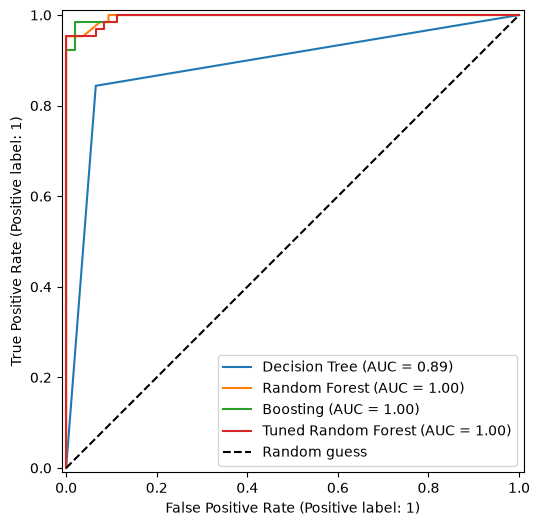

In [65]:
models["Tuned Random Forest"] = best_rf

fig, ax = plt.subplots(figsize=(8, 6))
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]
    print(f"{name}: Accuracy {accuracy_score(y_test, predictions):.3f} | "
          f"F1 {f1_score(y_test, predictions):.3f} | ROC-AUC {roc_auc_score(y_test, probs):.3f}")
    RocCurveDisplay.from_predictions(y_test, probs, name=name, ax=ax)

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.legend()
plt.show()

Ran accuracy, f1 and ROC-AUC for each of the models used here. Besides basic decision tree most models actually did very well on this dataset size and complexity. Actually basic Random forest beat my tuned version by 0.001 on ROC-AUC, I'm not sure if this was just lucky.

/As a side note, I added an extra .ipynb file on github. This is unreleated I just wanted to copy paste all of this and put in a bigger (19k rows, 10 features) dataset to see how well it did./